# Stage 3 (ASR) Validation: Whisper Results

Validates Whisper ASR outputs on Humyn LATAM Peruvian recordings (PER-1, PER-2).

This notebook:
1. Loads transcription.json outputs from the ASR pipeline
2. Compares against Humyn ground truth
3. Computes metrics: temporal alignment, speaker consistency, WER (Word Error Rate)
4. Visualizes results

## Setup & Load Data

In [49]:
import json
import pandas as pd
import numpy as np
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

REPO_ROOT = Path().resolve().parent
OUTPUT_BASE = REPO_ROOT / "data" / "ASR" / "tmp" / "test_asr"
HUMYN_TURNOS = REPO_ROOT / "hito-2" / "muestra" / "humyn" / "turnos.parquet"

print(f"Output base: {OUTPUT_BASE}")
print(f"Humyn ground truth: {HUMYN_TURNOS}")

Output base: /home/felipe/git/udesa/mia-taller-de-desarrollo/data/ASR/tmp/test_asr
Humyn ground truth: /home/felipe/git/udesa/mia-taller-de-desarrollo/hito-2/muestra/humyn/turnos.parquet


In [50]:
# Load ASR outputs (diarization + transcription)
outputs = {}
for test_id in ["PER-1", "PER-2"]:
    test_dir = OUTPUT_BASE / test_id
    
    with open(test_dir / "diarization.json") as f:
        diarization = json.load(f)
    
    trans_path = test_dir / "transcription.json"
    transcription = None
    if trans_path.exists():
        with open(trans_path) as f:
            transcription = json.load(f)
    
    outputs[test_id] = {
        "diarization": diarization,
        "transcription": transcription
    }
    
    status = "✓" if transcription else "✗"
    print(f"{status} {test_id}: Diarization={len(diarization['segments'])} segs, Transcription={'loaded' if transcription else 'missing'}")

✓ PER-1: Diarization=25 segs, Transcription=loaded
✓ PER-2: Diarization=38 segs, Transcription=loaded


In [51]:
# Load Humyn ground truth turns
import pyarrow.parquet as pq

humyn_df = pq.read_table(str(HUMYN_TURNOS)).to_pandas()
per1_turns = humyn_df[humyn_df["archivo"] == "Spanish_Peru_1.wav"]
per2_turns = humyn_df[humyn_df["archivo"] == "Spanish_Peru_2.wav"]

print(f"Loaded Humyn ground truth:")
print(f"  PER-1: {len(per1_turns)} turns")
print(f"  PER-2: {len(per2_turns)} turns")

Loaded Humyn ground truth:
  PER-1: 28 turns
  PER-2: 39 turns


## 1. Diarization Overview

**What it is:** The speaker segments extracted from Humyn metadata (one segment per Humyn turn).

In [52]:
for test_id in ["PER-1", "PER-2"]:
    diar = outputs[test_id]["diarization"]
    segs = diar["segments"]
    
    speakers = set(s["speaker"] for s in segs)
    duration = segs[-1]["end"] - segs[0]["start"]
    
    print(f"\n{test_id}:")
    print(f"  Segments: {len(segs)}")
    print(f"  Duration: {duration:.1f}s")
    print(f"  Speakers: {sorted(speakers)}")
    print(f"  First segment: {segs[0]['start']:.2f}s-{segs[0]['end']:.2f}s ({segs[0]['speaker']})")


PER-1:
  Segments: 25
  Duration: 659.9s
  Speakers: ['SPEAKER_00', 'SPEAKER_01']
  First segment: 0.06s-5.70s (SPEAKER_00)

PER-2:
  Segments: 38
  Duration: 628.3s
  Speakers: ['SPEAKER_00', 'SPEAKER_01']
  First segment: 1.72s-4.92s (SPEAKER_00)


## 2. Temporal Alignment: Diarization vs Ground Truth

**What this validates:** The `humyn_adapter.py` conversion (Humyn → diarization.json).
Since diarization comes directly from Humyn turns, timings should match exactly.

⚠️ **Does NOT test Whisper** — tests the preprocessing adapter only.

In [53]:
for test_id, truth_turns in [("PER-1", per1_turns), ("PER-2", per2_turns)]:
    diar = outputs[test_id]["diarization"]
    diar_segs = diar["segments"]
    
    # Filter out zero-duration turns (data quality issue in Humyn)
    truth_valid = truth_turns[truth_turns["fin"] > truth_turns["inicio"]].reset_index(drop=True)
    
    print(f"\n{test_id} Temporal Alignment:")
    print(f"  Diarization segments: {len(diar_segs)}")
    print(f"  Humyn turns (non-zero): {len(truth_valid)}")
    
    if len(diar_segs) != len(truth_valid):
        print(f"  ⚠️  MISMATCH in segment count!")
        continue
    
    # Compute timing differences
    start_diffs = []
    end_diffs = []
    
    for diar_seg, (_, turn) in zip(diar_segs, truth_valid.iterrows()):
        start_diffs.append(abs(diar_seg["start"] - turn["inicio"]))
        end_diffs.append(abs(diar_seg["end"] - turn["fin"]))
    
    print(f"  ✓ Segment counts match")
    print(f"  Timing precision:")
    print(f"    Start: mean={np.mean(start_diffs):.4f}s, max={max(start_diffs):.4f}s")
    print(f"    End:   mean={np.mean(end_diffs):.4f}s, max={max(end_diffs):.4f}s")


PER-1 Temporal Alignment:
  Diarization segments: 25
  Humyn turns (non-zero): 25
  ✓ Segment counts match
  Timing precision:
    Start: mean=0.0000s, max=0.0000s
    End:   mean=0.0000s, max=0.0000s

PER-2 Temporal Alignment:
  Diarization segments: 38
  Humyn turns (non-zero): 38
  ✓ Segment counts match
  Timing precision:
    Start: mean=0.0000s, max=0.0000s
    End:   mean=0.0000s, max=0.0000s


## 4. Transcription Output Summary

**What this shows:** Basic stats about the Whisper transcription results.

In [54]:
for test_id in ["PER-1", "PER-2"]:
    trans = outputs[test_id]["transcription"]
    
    if not trans:
        print(f"{test_id}: No transcription available")
        continue
    
    segs = trans["segments"]
    total_chars = sum(len(s["text"]) for s in segs)
    total_words = sum(len(s["text"].split()) for s in segs)
    duration = segs[-1]["end"] - segs[0]["start"]
    
    print(f"\n{test_id} Transcription Stats:")
    print(f"  Segments: {len(segs)}")
    print(f"  Duration: {duration:.1f}s")
    print(f"  Total words: {total_words}")
    print(f"  Total chars: {total_chars}")
    print(f"\n  Sample (first segment):")
    print(f"    [{segs[0]['start']:.2f}s-{segs[0]['end']:.2f}s] {segs[0]['speaker']}: {segs[0]['text'][:80]}...")


PER-1 Transcription Stats:
  Segments: 24
  Duration: 659.9s
  Total words: 1633
  Total chars: 9300

  Sample (first segment):
    [0.06s-5.70s] SPEAKER_00: una y mis del fin listo, uno. Y esto, sí,...

PER-2 Transcription Stats:
  Segments: 33
  Duration: 628.3s
  Total words: 1584
  Total chars: 8731

  Sample (first segment):
    [1.72s-4.92s] SPEAKER_00: ¿Cómo haces todo todavía?...


## 4. Segment-Level Coverage: Recall & Precision

**What this validates:** Did Whisper cover all speaker segments? Did it hallucinate extra segments?

Compares diarization segments (ground truth speaker turns) vs. predicted segments (Whisper output).

- **Recall**: % of diarization segments with at least one overlapping predicted segment
  - High (>80%): Whisper covered all speaker turns
  - Low: Whisper missed parts of the audio

- **Precision**: % of predicted segments with at least one overlapping diarization segment
  - High (>80%): Whisper did not hallucinate extra segments
  - Low: Whisper added fake segments outside diarization

PER-1 Per-Segment Coverage Ratio (GT Words / Assigned Words):
  Segments with 0 assigned words (excluded): 1

  First 5 segments:
  Segment 0: 13/10 = 1.30
  Segment 1: 2/2 = 1.00
  Segment 2: 8/7 = 1.14
  Segment 3: 4/3 = 1.33
  Segment 4: 38/34 = 1.12

  Statistics across all 24 segments:
count    24.000000
mean      1.135428
std       0.325539
min       0.500000
25%       1.049325
50%       1.097170
75%       1.132168
max       2.500000


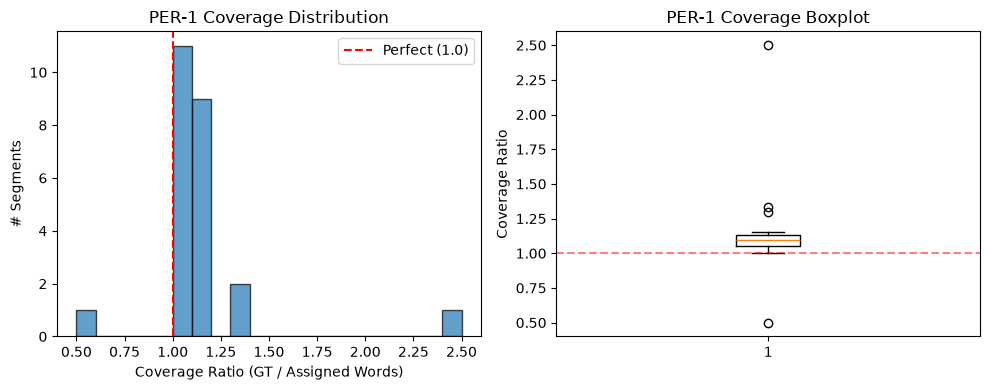


PER-2 Per-Segment Coverage Ratio (GT Words / Assigned Words):
  Segments with 0 assigned words (excluded): 5

  First 5 segments:
  Segment 0: 10/4 = 2.50
  Segment 1: 28/25 = 1.12
  Segment 2: 63/52 = 1.21
  Segment 4: 36/35 = 1.03
  Segment 5: 3/3 = 1.00

  Statistics across all 33 segments:
count    33.000000
mean      1.108676
std       0.303025
min       0.500000
25%       1.040000
50%       1.101695
75%       1.151515
max       2.500000


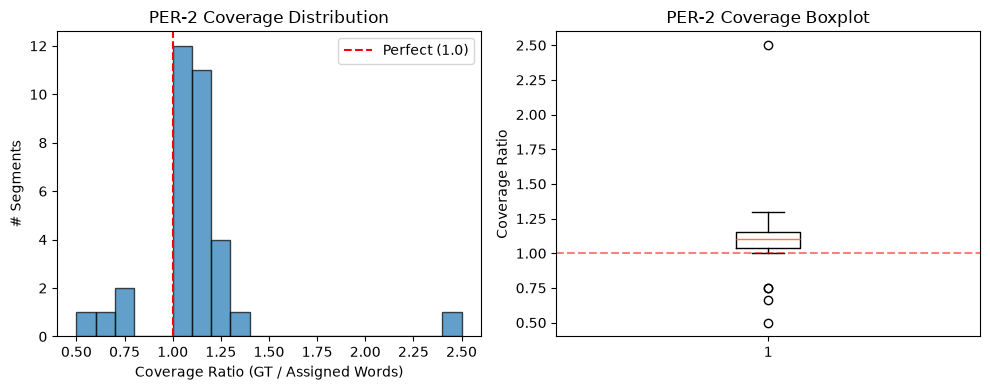

In [55]:
# Per-GT-segment coverage: GT words / words assigned to that segment by time window

import pandas as pd
import matplotlib.pyplot as plt

def count_words(text):
    """Count words in a text string."""
    return len(text.split()) if text and text.strip() else 0

for test_id, truth_turns in [("PER-1", per1_turns), ("PER-2", per2_turns)]:
    diar_segs = outputs[test_id]["diarization"]["segments"]
    trans = outputs[test_id]["transcription"]
    
    if not trans:
        print(f"{test_id}: No transcription available\n")
        continue
    
    trans_segs = trans["segments"]
    
    # Diarization segments were built one-per-turn from the non-zero-duration GT turns, in order
    truth_valid = truth_turns[truth_turns["fin"] > truth_turns["inicio"]].reset_index(drop=True)
    if len(truth_valid) != len(diar_segs):
        print(f"{test_id}: segment count mismatch ({len(truth_valid)} GT vs {len(diar_segs)} diar), skipping\n")
        continue
    
    coverage_ratios = []
    zero_assigned = 0
    details = []
    
    for i, d_seg in enumerate(diar_segs):
        gt_words = count_words(truth_valid["texto"].iloc[i])
        
        # Words assigned to this segment: Whisper words whose start is in [start, end)
        assigned_text = " ".join(
            t["text"] for t in trans_segs if d_seg["start"] <= t["start"] < d_seg["end"]
        )
        assigned_words = count_words(assigned_text)
        
        if assigned_words == 0:
            zero_assigned += 1
            continue
        
        ratio = gt_words / assigned_words
        coverage_ratios.append(ratio)
        
        if len(details) < 5:  # Show first 5 segments
            details.append(f"  Segment {i}: {gt_words}/{assigned_words} = {ratio:.2f}")
    
    # Statistics
    df = pd.DataFrame({"coverage_ratio": coverage_ratios})
    
    print(f"{test_id} Per-Segment Coverage Ratio (GT Words / Assigned Words):")
    print(f"  Segments with 0 assigned words (excluded): {zero_assigned}")
    print(f"\n  First 5 segments:")
    for detail in details:
        print(detail)
    
    print(f"\n  Statistics across all {len(coverage_ratios)} segments:")
    print(df["coverage_ratio"].describe().to_string())
    
    # Plot distribution
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.hist(coverage_ratios, bins=20, edgecolor="black", alpha=0.7)
    plt.xlabel("Coverage Ratio (GT / Assigned Words)")
    plt.ylabel("# Segments")
    plt.title(f"{test_id} Coverage Distribution")
    plt.axvline(1.0, color="red", linestyle="--", label="Perfect (1.0)")
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.boxplot(coverage_ratios, vert=True)
    plt.ylabel("Coverage Ratio")
    plt.title(f"{test_id} Coverage Boxplot")
    plt.axhline(1.0, color="red", linestyle="--", alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    print()

## 5. WER (Word Error Rate) — Whisper Accuracy

**What this validates:** Whisper's actual transcription quality.
Compares predicted text against Humyn ground truth.

✅ **This DOES test Whisper** — measures transcription accuracy.

- **WER = 0**: Perfect match
- **WER = 1**: Completely wrong

PER-1 Per-Segment WER Distribution:
  Total segments: 25

  Statistics:
count    25.000000
mean      0.484415
std       0.455432
min       0.139535
25%       0.184211
50%       0.283019
75%       0.750000
max       2.000000


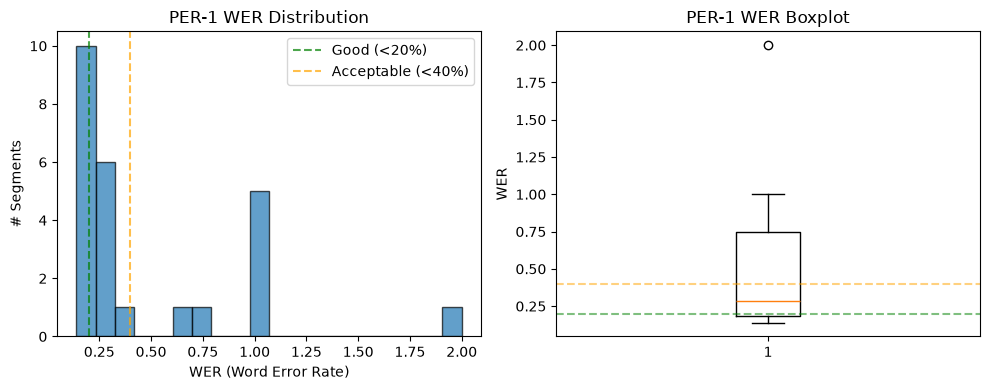


PER-2 Per-Segment WER Distribution:
  Total segments: 38

  Statistics:
count    38.000000
mean      0.574934
std       0.430183
min       0.150000
25%       0.250000
50%       0.394103
75%       0.950000
max       2.000000


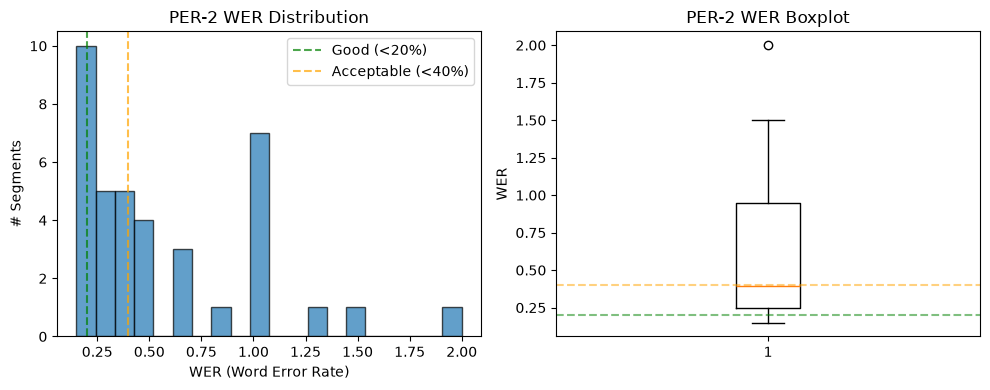

In [56]:
# Per-GT-segment WER: GT turn text vs words assigned to that segment by time window

import re

def _normalize(text):
    """Lowercase and strip punctuation so WER compares words, not formatting."""
    return re.sub(r"[^\w\s]", "", text.lower()).split()

def compute_wer(reference, hypothesis):
    """Word error rate: word-level edit distance / number of reference words."""
    ref = _normalize(reference)
    hyp = _normalize(hypothesis)
    if not ref:
        return 0.0 if not hyp else 1.0
    prev = list(range(len(hyp) + 1))
    for i, r in enumerate(ref, 1):
        cur = [i]
        for j, h in enumerate(hyp, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (r != h)))
        prev = cur
    return prev[-1] / len(ref)

for test_id, truth_turns in [("PER-1", per1_turns), ("PER-2", per2_turns)]:
    diar_segs = outputs[test_id]["diarization"]["segments"]
    trans = outputs[test_id]["transcription"]
    
    if not trans:
        print(f"{test_id}: Transcription not available\n")
        continue
    
    trans_segs = trans["segments"]
    
    truth_valid = truth_turns[truth_turns["fin"] > truth_turns["inicio"]].reset_index(drop=True)
    if len(truth_valid) != len(diar_segs):
        print(f"{test_id}: segment count mismatch ({len(truth_valid)} GT vs {len(diar_segs)} diar), skipping\n")
        continue
    
    per_segment_wers = []
    
    for i, d_seg in enumerate(diar_segs):
        gt_text = truth_valid["texto"].iloc[i]
        
        assigned_text = " ".join(
            t["text"] for t in trans_segs if d_seg["start"] <= t["start"] < d_seg["end"]
        )
        
        per_segment_wers.append(compute_wer(gt_text, assigned_text))
    
    # Statistics
    df_wer = pd.DataFrame({"wer": per_segment_wers})
    
    print(f"{test_id} Per-Segment WER Distribution:")
    print(f"  Total segments: {len(per_segment_wers)}")
    print(f"\n  Statistics:")
    print(df_wer["wer"].describe().to_string())
    
    # Plot distribution
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.hist(per_segment_wers, bins=20, edgecolor="black", alpha=0.7)
    plt.xlabel("WER (Word Error Rate)")
    plt.ylabel("# Segments")
    plt.title(f"{test_id} WER Distribution")
    plt.axvline(0.2, color="green", linestyle="--", label="Good (<20%)", alpha=0.7)
    plt.axvline(0.4, color="orange", linestyle="--", label="Acceptable (<40%)", alpha=0.7)
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.boxplot(per_segment_wers, vert=True)
    plt.ylabel("WER")
    plt.title(f"{test_id} WER Boxplot")
    plt.axhline(0.2, color="green", linestyle="--", alpha=0.5)
    plt.axhline(0.4, color="orange", linestyle="--", alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    print()


In [ ]:
# Inspect a single GT segment: its text, assigned transcription, and WER

def inspect_segment(test_id, seg_index):
    """Print GT text, assigned transcription and WER for one diarization segment."""
    diar_segs = outputs[test_id]["diarization"]["segments"]
    trans = outputs[test_id]["transcription"]
    truth_turns = per1_turns if test_id == "PER-1" else per2_turns
    truth_valid = truth_turns[truth_turns["fin"] > truth_turns["inicio"]].reset_index(drop=True)
    
    if not trans:
        print(f"{test_id}: Transcription not available")
        return
    if len(truth_valid) != len(diar_segs):
        print(f"{test_id}: segment count mismatch ({len(truth_valid)} GT vs {len(diar_segs)} diar)")
        return
    if not 0 <= seg_index < len(diar_segs):
        print(f"{test_id}: seg_index must be in [0, {len(diar_segs) - 1}]")
        return
    
    d_seg = diar_segs[seg_index]
    gt_text = truth_valid["texto"].iloc[seg_index]
    assigned_text = " ".join(
        t["text"] for t in trans["segments"] if d_seg["start"] <= t["start"] < d_seg["end"]
    )
    wer = compute_wer(gt_text, assigned_text)
    
    print(f"{test_id} segment {seg_index} [{d_seg['start']:.2f}s-{d_seg['end']:.2f}s] speaker={d_seg['speaker']}")
    print(f"\nGround truth:\n  {gt_text}")
    print(f"\nAssigned transcription:\n  {assigned_text or '(none)'}")
    print(f"\nWER: {wer:.2%}")

inspect_segment("PER-1", 1)


PER-1 segment 2 [7.72s-13.76s] speaker=SPEAKER_01

Ground truth:
  Bien, ¿qué tal? Buenas tardes, hermano. Eeeh, últimamente-

Assigned transcription:
  que tal, buena estar, hermano. Últimamente, todo

WER: 75.00%


## 6. Shift Scan: Is There a Constant Timing Offset?

**What this tests:** Whether a constant timing offset between Whisper and the ground truth explains the high WER.

- Add a constant `delta` to the start of every raw Whisper word (from `whisper_words.json`). Word text is unchanged.
- Assign words with the same rule as the pipeline: a shifted word belongs to a diarization segment if its start is in `[start, end)`.
- Recompute per-segment WER (same `compute_wer` as section 5) for each delta from -10 s to +10 s in 0.25 s steps.

**How to read it:** A real offset gives a smooth curve with a clear minimum near the true offset, and WER rises on both sides. A flat curve rules out a constant offset.

⚠️ The minimum is a diagnostic only. Choosing the best delta on these recordings is fitting, so any offset found must be explained and fixed at its source, not hardcoded.

PER-1 shift scan: 81 deltas from -10.00s to +10.00s
  delta=0:     median=26.42%, mean=48.10%
  best median: delta=+0.25s -> 24.53%
  best mean:   delta=+0.25s -> 43.87%


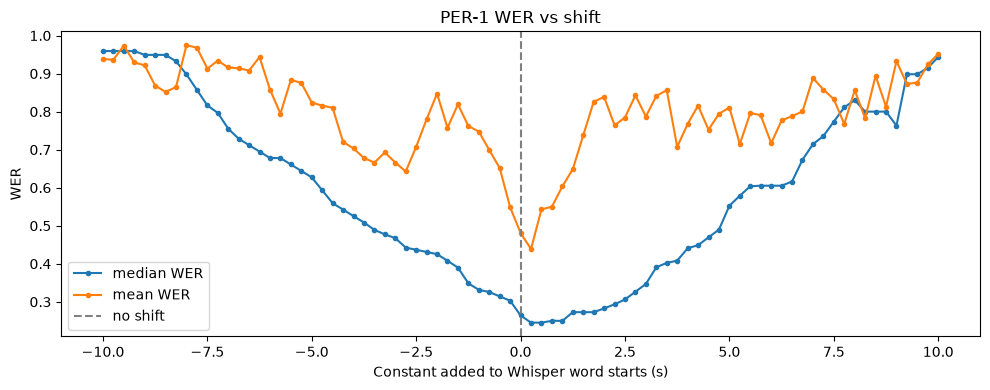


PER-2 shift scan: 81 deltas from -10.00s to +10.00s
  delta=0:     median=39.41%, mean=61.09%
  best median: delta=+1.00s -> 38.06%
  best mean:   delta=+0.50s -> 54.13%


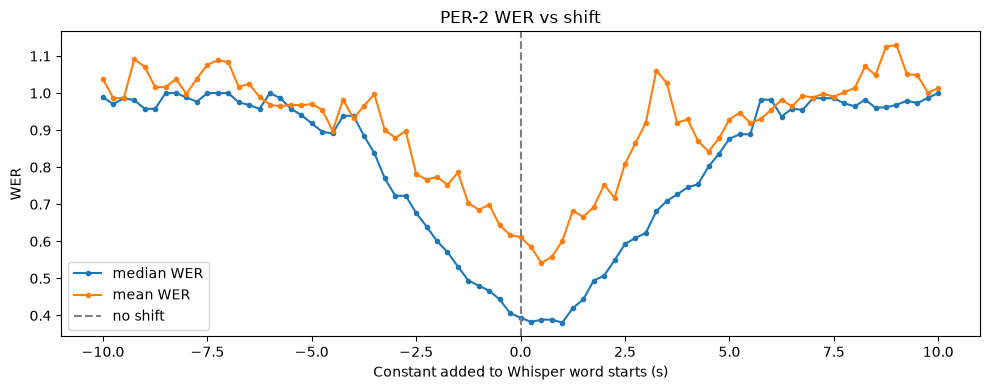

In [58]:
# Shift scan: add a constant delta to every raw Whisper word start and recompute per-segment WER
import bisect

SHIFT_DELTAS = np.round(np.arange(-10.0, 10.0 + 1e-9, 0.25), 2)

def assign_words(diar_segs, words, delta):
    """Assign shifted Whisper words to each diarization segment with the [start, end) rule."""
    starts = [w['start'] + delta for w in words]
    texts = [w['word'].strip() for w in words]
    assigned = []
    for d_seg in diar_segs:
        lo = bisect.bisect_left(starts, d_seg['start'])
        hi = bisect.bisect_left(starts, d_seg['end'])
        assigned.append(' '.join(texts[lo:hi]))
    return assigned

scan_results = {}
for test_id, truth_turns in [('PER-1', per1_turns), ('PER-2', per2_turns)]:
    words_path = OUTPUT_BASE / test_id / 'whisper_words.json'
    if not words_path.exists():
        print(f'{test_id}: whisper_words.json missing, skipping')
        continue
    with open(words_path, encoding='utf-8') as f:
        words = sorted(json.load(f)['words'], key=lambda w: w['start'])
    diar_segs = outputs[test_id]['diarization']['segments']
    truth_valid = truth_turns[truth_turns['fin'] > truth_turns['inicio']].reset_index(drop=True)
    if len(truth_valid) != len(diar_segs):
        print(f'{test_id}: segment count mismatch, skipping')
        continue

    rows = []
    for delta in SHIFT_DELTAS:
        assigned = assign_words(diar_segs, words, delta)
        wers = [compute_wer(truth_valid['texto'].iloc[i], text) for i, text in enumerate(assigned)]
        rows.append({'delta': delta, 'median': np.median(wers), 'mean': np.mean(wers)})
    df_scan = pd.DataFrame(rows)
    scan_results[test_id] = df_scan

    base = df_scan.loc[df_scan['delta'] == 0.0].iloc[0]
    best_med = df_scan.loc[df_scan['median'].idxmin()]
    best_mean = df_scan.loc[df_scan['mean'].idxmin()]
    print(f'{test_id} shift scan: {len(SHIFT_DELTAS)} deltas from {SHIFT_DELTAS[0]:+.2f}s to {SHIFT_DELTAS[-1]:+.2f}s')
    print(f"  delta=0:     median={base['median']:.2%}, mean={base['mean']:.2%}")
    print(f"  best median: delta={best_med['delta']:+.2f}s -> {best_med['median']:.2%}")
    print(f"  best mean:   delta={best_mean['delta']:+.2f}s -> {best_mean['mean']:.2%}")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(df_scan['delta'], df_scan['median'], marker='.', label='median WER')
    ax.plot(df_scan['delta'], df_scan['mean'], marker='.', label='mean WER')
    ax.axvline(0.0, color='gray', linestyle='--', label='no shift')
    ax.set_xlabel('Constant added to Whisper word starts (s)')
    ax.set_ylabel('WER')
    ax.set_title(f'{test_id} WER vs shift')
    ax.legend()
    plt.tight_layout()
    plt.show()
    print()


In [59]:
# PER-1 only: Humyn ground-truth turns and raw Whisper words, unprocessed
gt_per1 = per1_turns.rename(columns={'inicio': 'time_start', 'fin': 'time_end', 'hablante': 'speaker', 'texto': 'text'})[['time_start', 'time_end', 'speaker', 'text']].reset_index(drop=True)

with open(OUTPUT_BASE / 'PER-1' / 'whisper_words.json', encoding='utf-8') as f:
    whisper_raw = pd.DataFrame(json.load(f)['words']).rename(columns={'start': 'start_time', 'end': 'end_time'})

print(f'GT turns: {len(gt_per1)}')
print(f'Whisper raw words: {len(whisper_raw)}')
display(gt_per1.head())
display(whisper_raw.head())


GT turns: 28
Whisper raw words: 2340


,time_start,time_end,speaker,text
0,0.06,5.70,Speaker A,"Una, y ¿dónde está mi ce, mi teléfono? Listo, ..."
1,5.71,5.71,Speaker B,Bien
2,5.71,7.68,Speaker A,", comencemos."
3,7.72,13.76,Speaker B,"Bien, ¿qué tal? Buenas tardes, hermano. Eeeh, ..."
4,13.82,16.74,Speaker A,"Todo muy bien, hermano."


,word,start_time,end_time,probability
0,"una,",0.00,0.22,0.132006
1,una,0.38,1.70,0.969793
2,y,1.70,2.58,0.590400
3,mis,2.58,3.32,0.516912
4,del,3.32,3.82,0.096721


In [60]:
print(gt_per1.iloc[0]['text'])
gt_per1.iloc[0]

Una, y ¿dónde está mi ce, mi teléfono? Listo, uno. Listo. Eh, sí-


time_start                                                 0.06
time_end                                                    5.7
speaker                                               Speaker A
text          Una, y ¿dónde está mi ce, mi teléfono? Listo, ...
Name: 0, dtype: object

In [61]:
whisper_raw.head(60)

,word,start_time,end_time,probability
0,"una,",0.00,0.22,0.132006
1,una,0.38,1.70,0.969793
2,y,1.70,2.58,0.590400
3,mis,2.58,3.32,0.516912
4,del,3.32,3.82,0.096721
5,fin,3.82,4.02,0.113918
6,"listo,",4.02,4.28,0.944783
7,uno.,4.34,4.46,0.403647
8,Y,4.70,4.76,0.191437
9,"esto,",4.76,4.92,0.571100


In [62]:
# Playback of the test recordings. Linked by relative URL, not embedded, because each WAV is ~180 MB
from IPython.display import Audio, display

for test_id in ['PER-1', 'PER-2']:
    print(f'{test_id} audio:')
    display(Audio(url=f'../data/ASR/tmp/test_asr/{test_id}/audio.wav'))

PER-1 audio:


PER-2 audio:
